# Análisis Exploratorio de Datos (EDA)

### Objetivo

Este notebook realiza un **análisis exploratorio** del dataset y documenta, con evidencia, los **problemas de calidad de datos** y las **decisiones de preprocesamiento** que se tomarán antes de implementar los modelos.

El objetivo no es entrenar los modelos finales, sino responder preguntas como:

- ¿Qué contiene el dataset y cómo está estructurado?
- ¿Hay valores faltantes, duplicados, outliers o categorías problemáticas?
- ¿Cómo se distribuye la variable objetivo?
- ¿Qué riesgos hay para el Decision Tree y para Random Forest?
- ¿Qué decisiones de imputación, codificación y evaluación conviene tomar?

### Índice

1. Configuración y carga de datos
2. Diccionario de datos
3. Calidad de datos (faltantes, duplicados, dominios, categorías raras, outliers)
4. Variable objetivo
5. Análisis univariado
6. Problemas detectados y decisiones tomadas
7. Conclusiones del EDA

### Cómo ejecutar este notebook

- **Google Colab:** ejecutar todas las celdas. La primera celda de carga descarga el dataset desde UCI si no está disponible localmente.
- **Entorno local:** requiere `pandas`, `numpy`, `matplotlib` y `seaborn`. El dataset se busca en `data/processed.cleveland.data`.
- **Reproducibilidad:** se fija `RANDOM_STATE = 42` para todos los muestreos y gráficos que lo requieran.

La fuente de datos es el archivo **`processed.cleveland.data`** del repositorio UCI *Heart Disease* (id 45), el subconjunto procesado de Cleveland con 303 instancias y 14 atributos.

### Fuente

- **Dataset:** Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989). *Heart Disease* [Dataset]. UCI Machine Learning Repository. DOI: [10.24432/C52P4X](https://doi.org/10.24432/C52P4X).

El dataset original tiene 76 atributos, pero la versión estándar de experimentación usa un subconjunto de 14: 13 variables predictoras y la variable objetivo `num`.

---
## 1. Configuración y carga de datos

En esta sección se importan las librerías, se fija la semilla y se carga el dataset. La carga es robusta: si el archivo no existe localmente, se descarga desde UCI. Esto permite que el notebook funcione tanto en Colab como en un entorno local.

In [1]:
# ============================================================
# Configuración general
# ============================================================
import warnings
warnings.filterwarnings("ignore")

import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Estilo de gráficos
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["figure.autolayout"] = False

# Opciones de pandas
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Entorno listo.")
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("seaborn:", sns.__version__)

Entorno listo.
pandas : 3.1.0
numpy  : 2.5.4
seaborn: 0.13.2


In [2]:
# ============================================================
# Carga del dataset
# ============================================================
COLS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
DATA_PATH = DATA_DIR / "processed.cleveland.data"

URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
       "heart-disease/processed.cleveland.data")

if not DATA_PATH.exists():
    print("Archivo local no encontrado. Descargando desde UCI...")
    urllib.request.urlretrieve(URL, DATA_PATH)

df = pd.read_csv(DATA_PATH, header=None, names=COLS, na_values="?")

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dimensiones: 303 filas x 14 columnas


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.000,1.000,1.000,145.000,233.000,1.000,2.000,150.000,0.000,2.300,3.000,0.000,6.000,0
1,67.000,1.000,4.000,160.000,286.000,0.000,2.000,108.000,1.000,1.500,2.000,3.000,3.000,2
2,67.000,1.000,4.000,120.000,229.000,0.000,2.000,129.000,1.000,2.600,2.000,2.000,7.000,1
3,37.000,1.000,3.000,130.000,250.000,0.000,0.000,187.000,0.000,3.500,3.000,0.000,3.000,0
4,41.000,0.000,2.000,130.000,204.000,0.000,2.000,172.000,0.000,1.400,1.000,0.000,3.000,0


In [3]:
# Tipos inferidos, valores no nulos y cardinalidad
resumen_estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "nulos": df.isna().sum(),
    "n_unicos": df.nunique(),
})
resumen_estructura

,tipo,no_nulos,nulos,n_unicos
age,float64,303,0,41
sex,float64,303,0,2
cp,float64,303,0,4
trestbps,float64,303,0,50
chol,float64,303,0,152
fbs,float64,303,0,2
restecg,float64,303,0,3
thalach,float64,303,0,91
exang,float64,303,0,2
oldpeak,float64,303,0,40


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [5]:
# Muestra aleatoria reproducible para inspección visual
df.sample(10, random_state=RANDOM_STATE)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
179,53.000,1.000,3.000,130.000,246.000,1.000,2.000,173.000,0.000,0.000,1.000,3.000,3.000,0
228,54.000,1.000,4.000,110.000,206.000,0.000,2.000,108.000,1.000,0.000,2.000,1.000,3.000,3
111,56.000,1.000,4.000,125.000,249.000,1.000,2.000,144.000,1.000,1.200,2.000,1.000,3.000,1
246,58.000,1.000,4.000,100.000,234.000,0.000,0.000,156.000,0.000,0.100,1.000,1.000,7.000,2
60,51.000,0.000,4.000,130.000,305.000,0.000,0.000,142.000,1.000,1.200,2.000,0.000,7.000,2
9,53.000,1.000,4.000,140.000,203.000,1.000,2.000,155.000,1.000,3.100,3.000,0.000,7.000,1
119,65.000,1.000,4.000,135.000,254.000,0.000,2.000,127.000,0.000,2.800,2.000,1.000,7.000,2
223,53.000,1.000,4.000,123.000,282.000,0.000,0.000,95.000,1.000,2.000,2.000,2.000,7.000,3
268,40.000,1.000,4.000,152.000,223.000,0.000,0.000,181.000,0.000,0.000,1.000,0.000,7.000,1
33,59.000,1.000,4.000,135.000,234.000,0.000,0.000,161.000,0.000,0.500,2.000,0.000,7.000,0


In [6]:
# Estadísticos descriptivos de todas las columnas
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
age,303.000,54.439,9.039,29.000,48.000,56.000,61.000,77.000
sex,303.000,0.680,0.467,0.000,0.000,1.000,1.000,1.000
cp,303.000,3.158,0.960,1.000,3.000,3.000,4.000,4.000
trestbps,303.000,131.690,17.600,94.000,120.000,130.000,140.000,200.000
chol,303.000,246.693,51.777,126.000,211.000,241.000,275.000,564.000
fbs,303.000,0.149,0.356,0.000,0.000,0.000,0.000,1.000
restecg,303.000,0.990,0.995,0.000,0.000,1.000,2.000,2.000
thalach,303.000,149.607,22.875,71.000,133.500,153.000,166.000,202.000
exang,303.000,0.327,0.470,0.000,0.000,0.000,1.000,1.000
oldpeak,303.000,1.040,1.161,0.000,0.000,0.800,1.600,6.200


**Lectura de la estructura**

- El dataset tiene **303 filas** y **14 columnas**: 13 features y el target `num`.
- Todas las columnas se cargan como `float64` salvo `num` (`int64`). Esto ocurre porque `ca` y `thal` tienen faltantes y Pandas promueve el tipo a flotante. Es un detalle importante: **un atributo categórico no debe tratarse como numérico** solo porque esté codificado con números.
- No hay columnas de texto ni identificadores. Todas las variables son clínicas y numéricamente codificadas.
- La cardinalidad es baja: entre 2 y 4 valores distintos por variable categórica. Es un dataset pequeño, adecuado para implementar y auditar un árbol de decisión desde cero.

---
## 2. Diccionario de datos

La siguiente tabla resume el significado de cada variable, su tipo estadístico, su rol y los valores observados. La información proviene de la documentación oficial de UCI y del archivo `processed.cleveland.data`.

| Variable | Tipo | Rol | Valores / unidad | Faltantes |
|---|---|---|---|---|
| `age` | Numérica continua | Feature | Años (29–77 en esta muestra) | 0 |
| `sex` | Categórica binaria | Feature | 0 = femenino, 1 = masculino | 0 |
| `cp` | Categórica nominal | Feature | 1 = angina típica, 2 = angina atípica, 3 = dolor no anginal, 4 = asintomático | 0 |
| `trestbps` | Numérica continua | Feature | Presión arterial en reposo (mm Hg) | 0 |
| `chol` | Numérica continua | Feature | Colesterol sérico (mg/dl) | 0 |
| `fbs` | Categórica binaria | Feature | Glucemia en ayunas > 120 mg/dl (0 = no, 1 = sí) | 0 |
| `restecg` | Categórica nominal | Feature | 0 = normal, 1 = anomalía ST-T, 2 = hipertrofia ventricular izquierda | 0 |
| `thalach` | Numérica continua | Feature | Frecuencia cardíaca máxima alcanzada (lpm) | 0 |
| `exang` | Categórica binaria | Feature | Angina inducida por ejercicio (0 = no, 1 = sí) | 0 |
| `oldpeak` | Numérica continua | Feature | Depresión del segmento ST inducida por ejercicio | 0 |
| `slope` | Categórica ordinal | Feature | 1 = ascendente, 2 = plano, 3 = descendente | 0 |
| `ca` | Categórica discreta | Feature | Número de vasos principales coloreados por fluoroscopía (0–3) | 4 |
| `thal` | Categórica nominal | Feature | 3 = normal, 6 = defecto fijo, 7 = defecto reversible | 2 |
| `num` | Target original | Target | 0 = sin enfermedad (< 50% de estrechamiento); 1–4 = con enfermedad (> 50%) | 0 |

**Sobre el target.** `num` es una **variable ordinal de severidad**, no una mera etiqueta nominal: 0 indica ausencia de enfermedad y 1–4 indican presencia con distinto grado. La práctica estándar en este dataset es colapsar a **binario** (`0` vs. `> 0`), que es lo que haremos. Más adelante se discute la alternativa multiclase y por qué no es la opción principal.

---
## 3. Calidad de datos

Esta sección revisa, uno por uno, los problemas que pueden afectar el entrenamiento de los modelos:

1. Valores faltantes.
2. Duplicados.
3. Valores fuera de dominio.
4. Categorías raras o casi constantes.
5. Outliers en variables continuas.

Para cada problema se documenta **la evidencia**, **el riesgo** y **la decisión**.

### 3.1 Valores faltantes

Primero cuantificamos los faltantes por columna y por fila. También revisamos el **patrón** de faltantes, porque no es lo mismo que falte una variable al azar que tener filas sistemáticamente incompletas.

In [7]:
faltantes = pd.DataFrame({
    "n_faltantes": df.isna().sum(),
    "pct_faltantes": (df.isna().mean() * 100).round(2),
}).query("n_faltantes > 0").sort_values("n_faltantes", ascending=False)

faltantes

,n_faltantes,pct_faltantes
ca,4,1.320
thal,2,0.660


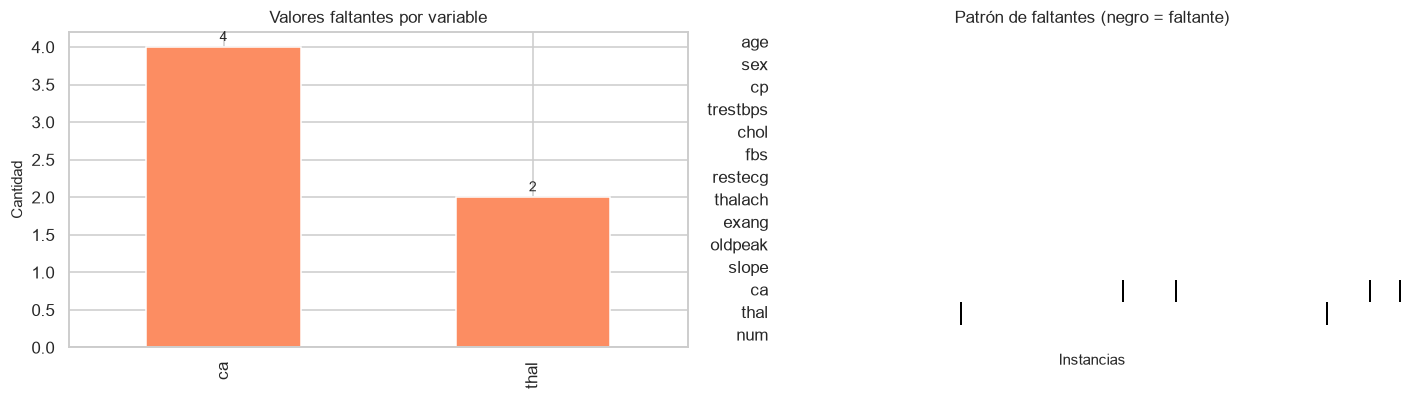

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

# Barras de faltantes
faltantes["n_faltantes"].plot(kind="bar", ax=axes[0], color="#fc8d62")
axes[0].set_title("Valores faltantes por variable")
axes[0].set_ylabel("Cantidad")
axes[0].set_xlabel("")
for i, v in enumerate(faltantes["n_faltantes"]):
    axes[0].text(i, v + 0.08, str(int(v)), ha="center", fontsize=9)

# Mapa de faltantes
sns.heatmap(df.isna().T, cbar=False, cmap="Greys", ax=axes[1],
            xticklabels=False, yticklabels=True)
axes[1].set_title("Patrón de faltantes (negro = faltante)")
axes[1].set_xlabel("Instancias")

plt.tight_layout()
plt.show()

In [9]:
filas_con_faltantes = df[df.isna().any(axis=1)].copy()
print(f"Filas afectadas: {len(filas_con_faltantes)} "
      f"({len(filas_con_faltantes) / len(df) * 100:.2f}% del total)")
filas_con_faltantes

Filas afectadas: 6 (1.98% del total)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.000,0.000,3.000,128.000,216.000,0.000,2.000,115.000,0.000,0.000,1.000,0.000,NaN,0
166,52.000,1.000,3.000,138.000,223.000,0.000,0.000,169.000,0.000,0.000,1.000,NaN,3.000,0
192,43.000,1.000,4.000,132.000,247.000,1.000,2.000,143.000,1.000,0.100,2.000,NaN,7.000,1
266,52.000,1.000,4.000,128.000,204.000,1.000,0.000,156.000,1.000,1.000,2.000,0.000,NaN,2
287,58.000,1.000,2.000,125.000,220.000,0.000,0.000,144.000,0.000,0.400,2.000,NaN,7.000,0
302,38.000,1.000,3.000,138.000,175.000,0.000,0.000,173.000,0.000,0.000,1.000,NaN,3.000,0


In [10]:
def nombre_patron(row):
    columnas = row.index[row.values].tolist()
    return " + ".join(columnas) if columnas else "sin faltantes"

patron = df.isna().apply(nombre_patron, axis=1)
patron.value_counts()

sin faltantes    297
ca                 4
thal               2
Name: count, dtype: int64

**Evidencia**

- Solo **6 filas** tienen faltantes: **4 en `ca`** y **2 en `thal`**.
- En total, hay **6 filas afectadas** (1.98% del dataset). Ninguna fila tiene faltantes en más de una variable.
- No hay un patrón sistemático: son casos aislados, no un bloque de pacientes sin estudios.
- Las dos variables son clínicamente relevantes, así que la decisión de imputación merece atención.

**Riesgo**

- Eliminar las 6 filas reduce el dataset a 297 casos. Es una pérdida pequeña, pero afecta justo a variables clínicamente relevantes.
- Imputar con la mediana/moda introduce un sesgo pequeño y artificial en esas 6 filas.
- Si se imputa usando todo el dataset antes del split, se produce *data leakage*. La imputación debe **ajustarse solo con el conjunto de entrenamiento** y aplicarse al de test.

**Decisión**

- **Imputar** `ca` con la mediana y `thal` con la moda (o mediana, que coincide). Son 6 filas y la distorsión es mínima.
- En la etapa de modelado, la imputación se hará **dentro del pipeline de entrenamiento**, ajustando con train y transformando test.
- Se hará un **chequeo de sensibilidad** comparando “eliminar” vs. “imputar” (sección 6.3). Si las conclusiones no cambian, se reporta imputación como estrategia principal.

### 3.2 Duplicados y columnas constantes

Los duplicados exactos pueden inflar métricas si quedan repartidos entre train y test. Las columnas constantes no aportan información y complican algunos cálculos.

In [11]:
print("Duplicados exactos:", int(df.duplicated().sum()))
print("Filas únicas:", len(df.drop_duplicates()))
print("Columnas constantes:", [c for c in df.columns if df[c].nunique(dropna=True) == 1])

Duplicados exactos: 0
Filas únicas: 303
Columnas constantes: []


**Resultado:** no hay duplicados exactos ni columnas constantes. El dataset está limpio en ese aspecto. No se elimina ninguna fila por duplicación.

### 3.3 Validación de dominios

Antes de modelar conviene verificar que los valores estén dentro de los rangos clínicamente plausibles y de los conjuntos definidos por la documentación. Esto detecta errores de carga, codificaciones inesperadas o valores centinela (por ejemplo, `0` o `-1` usados como “desconocido”).

In [12]:
reglas = {
    "sex":      {"tipo": "conjunto", "valores": {0, 1}},
    "cp":       {"tipo": "conjunto", "valores": {1, 2, 3, 4}},
    "fbs":      {"tipo": "conjunto", "valores": {0, 1}},
    "restecg":  {"tipo": "conjunto", "valores": {0, 1, 2}},
    "exang":    {"tipo": "conjunto", "valores": {0, 1}},
    "slope":    {"tipo": "conjunto", "valores": {1, 2, 3}},
    "ca":       {"tipo": "conjunto", "valores": {0, 1, 2, 3}},
    "thal":     {"tipo": "conjunto", "valores": {3, 6, 7}},
    "num":      {"tipo": "conjunto", "valores": {0, 1, 2, 3, 4}},
    "age":      {"tipo": "rango", "min": 18, "max": 100},
    "trestbps": {"tipo": "rango", "min": 80, "max": 250},
    "chol":     {"tipo": "rango", "min": 100, "max": 600},
    "thalach":  {"tipo": "rango", "min": 60, "max": 220},
    "oldpeak":  {"tipo": "rango", "min": -1, "max": 10},
}

filas = []
for col, regla in reglas.items():
    s = df[col]
    if regla["tipo"] == "conjunto":
        invalidos = s.notna() & ~s.isin(regla["valores"])
        detalle = f"valores permitidos: {sorted(regla['valores'])}"
    else:
        invalidos = s.notna() & ((s < regla["min"]) | (s > regla["max"]))
        detalle = f"rango: [{regla['min']}, {regla['max']}]"
    filas.append({
        "variable": col,
        "regla": detalle,
        "invalidos": int(invalidos.sum()),
        "ejemplos": s[invalidos].head(3).tolist(),
    })

validacion = pd.DataFrame(filas)
validacion

,variable,regla,invalidos,ejemplos
0,sex,"valores permitidos: [0, 1]",0,[]
1,cp,"valores permitidos: [1, 2, 3, 4]",0,[]
2,fbs,"valores permitidos: [0, 1]",0,[]
3,restecg,"valores permitidos: [0, 1, 2]",0,[]
4,exang,"valores permitidos: [0, 1]",0,[]
5,slope,"valores permitidos: [1, 2, 3]",0,[]
6,ca,"valores permitidos: [0, 1, 2, 3]",0,[]
7,thal,"valores permitidos: [3, 6, 7]",0,[]
8,num,"valores permitidos: [0, 1, 2, 3, 4]",0,[]
9,age,"rango: [18, 100]",0,[]


**Resultado:** todas las variables respetan los dominios esperados. No hay valores centinela ni códigos fuera de rango. En particular:

- No hay `chol = 0`, `trestbps = 0` ni `thalach = 0` (valores que a veces aparecen como “missing” encubierto).
- `oldpeak` admite `0` legítimamente (ausencia de depresión del ST).
- Los códigos de `cp`, `restecg`, `slope`, `ca`, `thal` y `num` coinciden con la documentación.

**Decisión:** no se corrige ni se elimina ningún valor por dominio.

### 3.4 Categorías raras y variables casi constantes

En un árbol de decisión, una categoría con muy pocos casos puede generar una rama con 1–3 ejemplos. Esas ramas son estadísticamente inestables: un cambio pequeño en el train set puede hacer desaparecer o aparecer la rama, y el árbol puede sobreajustar. En Random Forest el problema se atenúa por el bagging, pero no desaparece.

In [13]:
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

registros = []
for c in cat_cols:
    vc = df[c].value_counts(dropna=False).sort_index()
    for valor, n in vc.items():
        registros.append({
            "variable": c,
            "valor": valor,
            "n": int(n),
            "pct": round(100 * n / len(df), 2),
        })

frecuencias = pd.DataFrame(registros)

# Tabla de frecuencias sobre casos válidos (los faltantes se reportan en 3.1)
frecuencias_validas = frecuencias.dropna(subset=["valor"]).copy()
n_validos = df[cat_cols].notna().sum()
frecuencias_validas["n_validos"] = frecuencias_validas["variable"].map(n_validos)
frecuencias_validas["pct"] = (
    100 * frecuencias_validas["n"] / frecuencias_validas["n_validos"]
).round(2)
frecuencias_validas["valor"] = frecuencias_validas["valor"].astype(int)
frecuencias_validas.sort_values(["variable", "valor"]).reset_index(drop=True)

,variable,valor,n,pct,n_validos
0,ca,0,176,58.860,299
1,ca,1,65,21.740,299
2,ca,2,38,12.710,299
3,ca,3,20,6.690,299
4,cp,1,23,7.590,303
5,cp,2,50,16.500,303
6,cp,3,86,28.380,303
7,cp,4,144,47.520,303
8,exang,0,204,67.330,303
9,exang,1,99,32.670,303


In [14]:
# Categorías con menos del 10% de los casos válidos
raras = frecuencias_validas[
    frecuencias_validas["pct"] < 10
].sort_values(["variable", "pct"])
raras

,variable,valor,n,pct,n_validos
19,ca,3,20,6.690,299
2,cp,1,23,7.590,303
9,restecg,1,4,1.320,303
15,slope,3,21,6.930,303
22,thal,6,18,5.980,301


**Evidencia**

- `restecg = 1` tiene solo **4 casos** (1.3%). Es la categoría más frágil.
- `thal = 6` tiene **18 casos** (6.0%).
- `ca = 3` tiene **20 casos** (6.7%).
- `slope = 3` tiene **21 casos** (6.9%).
- `cp = 1` tiene **23 casos** (7.6%): es la categoría más chica de `cp`, pero conserva masa suficiente.
- `fbs = 1` tiene **45 casos** (14.9%): no es rara, pero está desbalanceada.
- `sex = 1` (masculino) concentra el **68%** de la muestra; `sex = 0` el 32%.

**Riesgo**

- Un split multiway sobre `restecg` puede crear una hoja con 4 casos (o menos, si además se cruza con otra variable). Esa hoja tendrá una estimación de clase muy ruidosa.
- En el DT, el criterio de ganancia puede preferir un atributo con muchas categorías raras por una mejora espuria de impureza (sesgo hacia atributos con alta cardinalidad).
- En RF, las categorías raras aparecen en muchas muestras bootstrap y pueden generar splits inestables.

**Decisión**

- **Mantener** las categorías originales en el experimento principal, porque son clínicamente significativas y el dataset es pequeño.
- Usar **`min_samples_leaf`** y/o el **`threshold`** para evitar hojas de 1–2 casos.
- Como **análisis de sensibilidad**, evaluar una variante donde `restecg = 1` se agrupa con `restecg = 2` (ambas son anormalidades electrocardiográficas). Si el rendimiento no cambia, se reporta la codificación original.
- No agrupar `thal = 6` ni `ca = 3` ni `slope = 3`: tienen suficiente masa (18–21 casos) y son categorías con significado clínico propio.

### 3.5 Outliers en variables continuas

Se usa el criterio clásico de **IQR (1.5 × rango intercuartílico)**. Es una regla descriptiva, no una verdad absoluta: en datos clínicos, los valores extremos pueden ser pacientes reales y no errores de medición.

In [15]:
cont_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

filas = []
for c in cont_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < li) | (s > ls)).sum())
    filas.append({
        "variable": c,
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "limite_inf": li, "limite_sup": ls,
        "n_outliers": n_out,
        "pct_outliers": round(100 * n_out / len(s), 2),
        "min": s.min(), "max": s.max(),
    })

outliers = pd.DataFrame(filas)
outliers

,variable,Q1,Q3,IQR,limite_inf,limite_sup,n_outliers,pct_outliers,min,max
0,age,48.000,61.000,13.000,28.500,80.500,0,0.000,29.000,77.000
1,trestbps,120.000,140.000,20.000,90.000,170.000,9,2.970,94.000,200.000
2,chol,211.000,275.000,64.000,115.000,371.000,5,1.650,126.000,564.000
3,thalach,133.500,166.000,32.500,84.750,214.750,1,0.330,71.000,202.000
4,oldpeak,0.000,1.600,1.600,-2.400,4.000,5,1.650,0.000,6.200


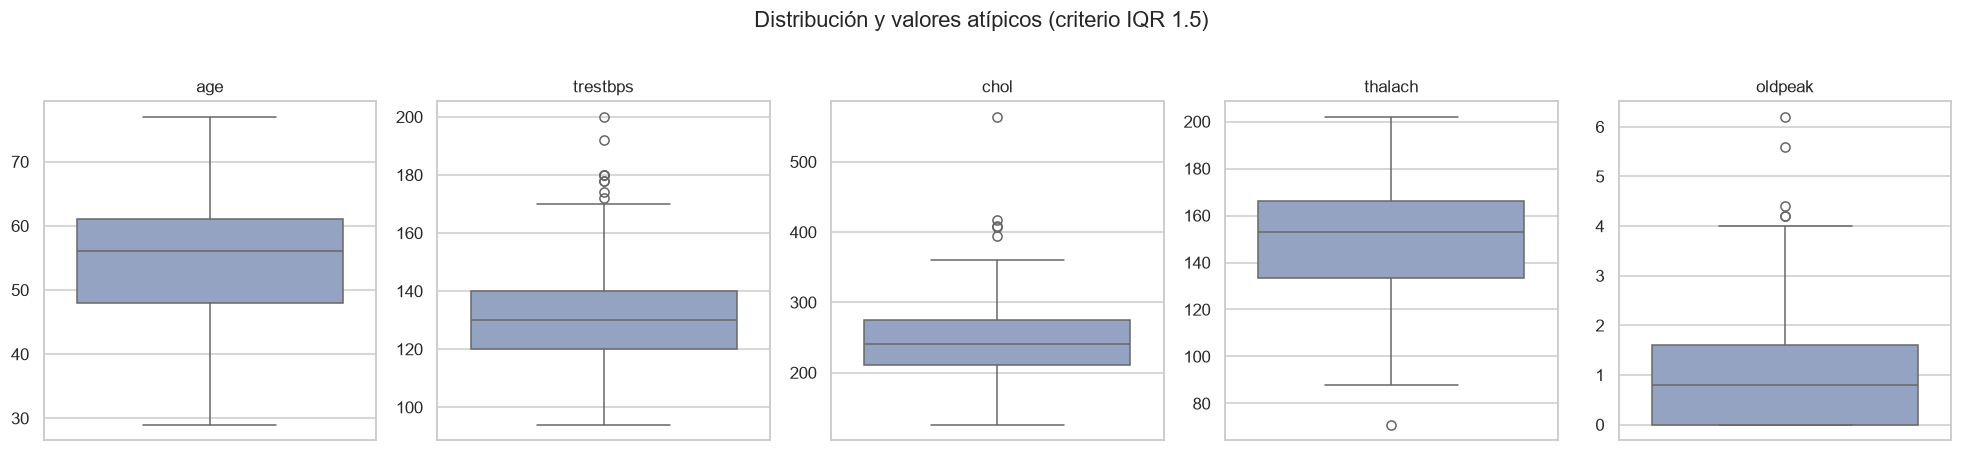

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, cont_cols):
    sns.boxplot(y=df[c], ax=ax, color="#8da0cb")
    ax.set_title(c)
    ax.set_ylabel("")

plt.suptitle("Distribución y valores atípicos (criterio IQR 1.5)", y=1.02)
plt.tight_layout()
plt.show()

**Evidencia**

- `trestbps`: 9 outliers (3.0%). Máximo 200 mm Hg.
- `chol`: 5 outliers (1.7%). Máximo 564 mg/dl (un valor muy alto, pero clínicamente posible).
- `oldpeak`: 5 outliers (1.7%). Máximo 6.2.
- `thalach`: 1 outlier (0.3%). Mínimo 71 lpm.
- `age`: 0 outliers por IQR.

Además, hay asimetrías visibles: `chol` (asimetría 1.14) y `oldpeak` (1.27) tienen cola derecha; `thalach` tiene cola izquierda (−0.54). `oldpeak` tiene un **32.7% de ceros**, lo que refleja ausencia de depresión del ST y no un error.

**Riesgo**

- Un árbol de decisión es **invariante a transformaciones monótonas** y no se ve afectado por la escala ni por la magnitud de los outliers: solo le importa el orden de los valores. Por eso, en principio, no es necesario recortarlos.
- Sin embargo, un outlier extremo puede generar un **punto de corte aislado** que separe un único caso. Eso puede ser sobreajuste, especialmente si el árbol no tiene `min_samples_leaf`.
- En RF, el efecto es menor por el promedio de muchos árboles.

**Decisión**

- **No eliminar ni recortar** outliers en el experimento principal. Los valores son plausibles y el árbol es robusto.
- Controlar el sobreajuste con `min_samples_leaf`, `min_samples_split` y el `threshold`.
- Como análisis de sensibilidad, evaluar *winsorización* al percentil 1–99 solo para verificar que las conclusiones no dependan de los extremos. No se usará como opción principal.

---
## 4. Variable objetivo

El target original `num` tiene 5 valores. Analizamos su distribución y justificamos la construcción del target binario.

In [17]:
conteo_num = df["num"].value_counts().sort_index()

conteo_bin = df["num"].gt(0).map({True: "1 (con enfermedad)",
                                  False: "0 (sin enfermedad)"})
conteo_bin = conteo_bin.value_counts().reindex(
    ["0 (sin enfermedad)", "1 (con enfermedad)"])
conteo_bin.index.name = None

print("Target original:")
print(conteo_num.to_string())
print("\nTarget binario:")
print(conteo_bin.to_string())

Target original:
num
0    164
1     55
2     36
3     35
4     13

Target binario:
0 (sin enfermedad)    164
1 (con enfermedad)    139


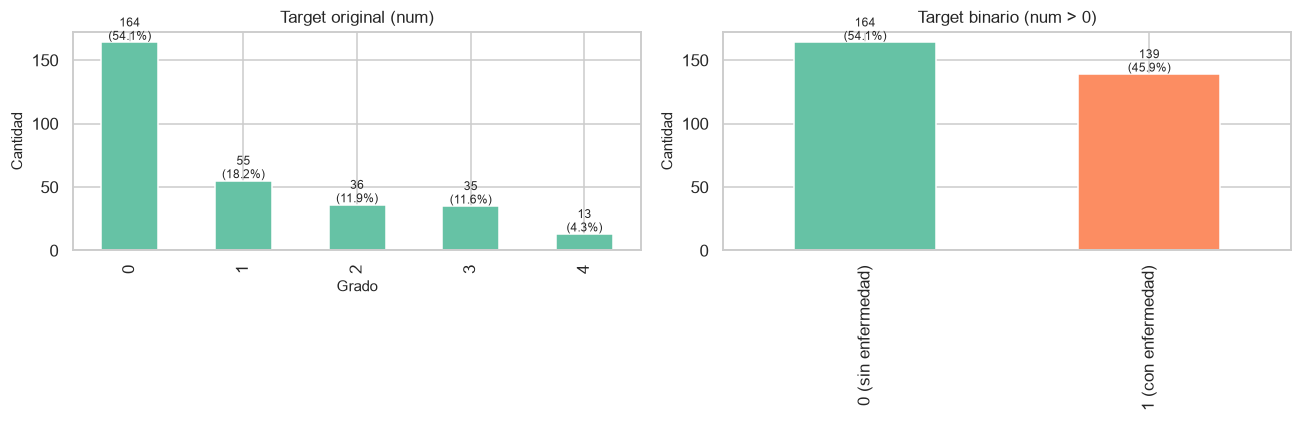

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

conteo_num.plot(kind="bar", ax=axes[0], color="#66c2a5")
axes[0].set_title("Target original (num)")
axes[0].set_xlabel("Grado")
axes[0].set_ylabel("Cantidad")
for i, v in enumerate(conteo_num):
    axes[0].text(i, v + 2, f"{v}\n({100 * v / len(df):.1f}%)",
                 ha="center", fontsize=8)

conteo_bin.plot(kind="bar", ax=axes[1], color=["#66c2a5", "#fc8d62"])
axes[1].set_title("Target binario (num > 0)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Cantidad")
for i, v in enumerate(conteo_bin):
    axes[1].text(i, v + 2, f"{v}\n({100 * v / len(df):.1f}%)",
                 ha="center", fontsize=8)

plt.tight_layout()
plt.show()

In [19]:
# Construcción del target binario
df["target"] = (df["num"] > 0).astype(int)

tasa = df["target"].mean() * 100
baseline = (df["target"] == 0).mean() * 100
print(f"Tasa de enfermedad: {tasa:.2f}%")
print(f"Accuracy de la clase mayoritaria (baseline trivial): {baseline:.2f}%")

Tasa de enfermedad: 45.87%
Accuracy de la clase mayoritaria (baseline trivial): 54.13%


**Evidencia**

| `num` | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| Casos | 164 | 55 | 36 | 35 | 13 |
| % | 54.1% | 18.2% | 11.9% | 11.6% | 4.3% |

- El target binario queda en **164 sanos (54.1%)** y **139 enfermos (45.9%)**: está razonablemente balanceado.
- El target multiclase está fuertemente desbalanceado: la clase 4 tiene solo 13 casos y la clase 0 concentra más de la mitad.
- El **baseline trivial** (predecir siempre “sano”) alcanza **54.1% de accuracy**. Cualquier modelo debe superar claramente ese valor para ser útil.

**Decisión**

- Usar **target binario** (`0` vs. `> 0`) como escenario principal.
- Justificación: es la formulación estándar del dataset, evita el problema de clases con 13 casos, permite métricas robustas (sensibilidad, especificidad, ROC-AUC) y es clínicamente interpretable (“presencia o ausencia de enfermedad”).
- El escenario multiclase se menciona como **extensión** y no se usa como comparación principal, porque el desbalance haría que accuracy y F1 macro sean difíciles de interpretar con tan pocos casos por clase.
- En todos los experimentos se reportará **accuracy, precisión, recall/sensibilidad, F1, especificidad y ROC-AUC**, además de la matriz de confusión. La accuracy sola no alcanza.

---
## 5. Análisis univariado

Analizamos cada variable por separado para entender su distribución, escala, forma y valores típicos. Esto ayuda a detectar transformaciones necesarias, escalas incompatibles y variables con poca variabilidad.

### 5.1 Variables continuas

Resumen de tendencia central, dispersión, asimetría y curtosis. El coeficiente de variación (CV) permite comparar la dispersión relativa entre variables con escalas muy distintas.

In [20]:
resumen_cont = df[cont_cols].describe().T
resumen_cont["asimetria"] = df[cont_cols].skew()
resumen_cont["curtosis"] = df[cont_cols].kurt()
resumen_cont["CV_%"] = (resumen_cont["std"] / resumen_cont["mean"] * 100).round(2)
resumen_cont

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis,CV_%
age,303.000,54.439,9.039,29.000,48.000,56.000,61.000,77.000,-0.209,-0.523,16.600
trestbps,303.000,131.690,17.600,94.000,120.000,130.000,140.000,200.000,0.706,0.880,13.360
chol,303.000,246.693,51.777,126.000,211.000,241.000,275.000,564.000,1.136,4.492,20.990
thalach,303.000,149.607,22.875,71.000,133.500,153.000,166.000,202.000,-0.537,-0.054,15.290
oldpeak,303.000,1.040,1.161,0.000,0.000,0.800,1.600,6.200,1.270,1.576,111.680


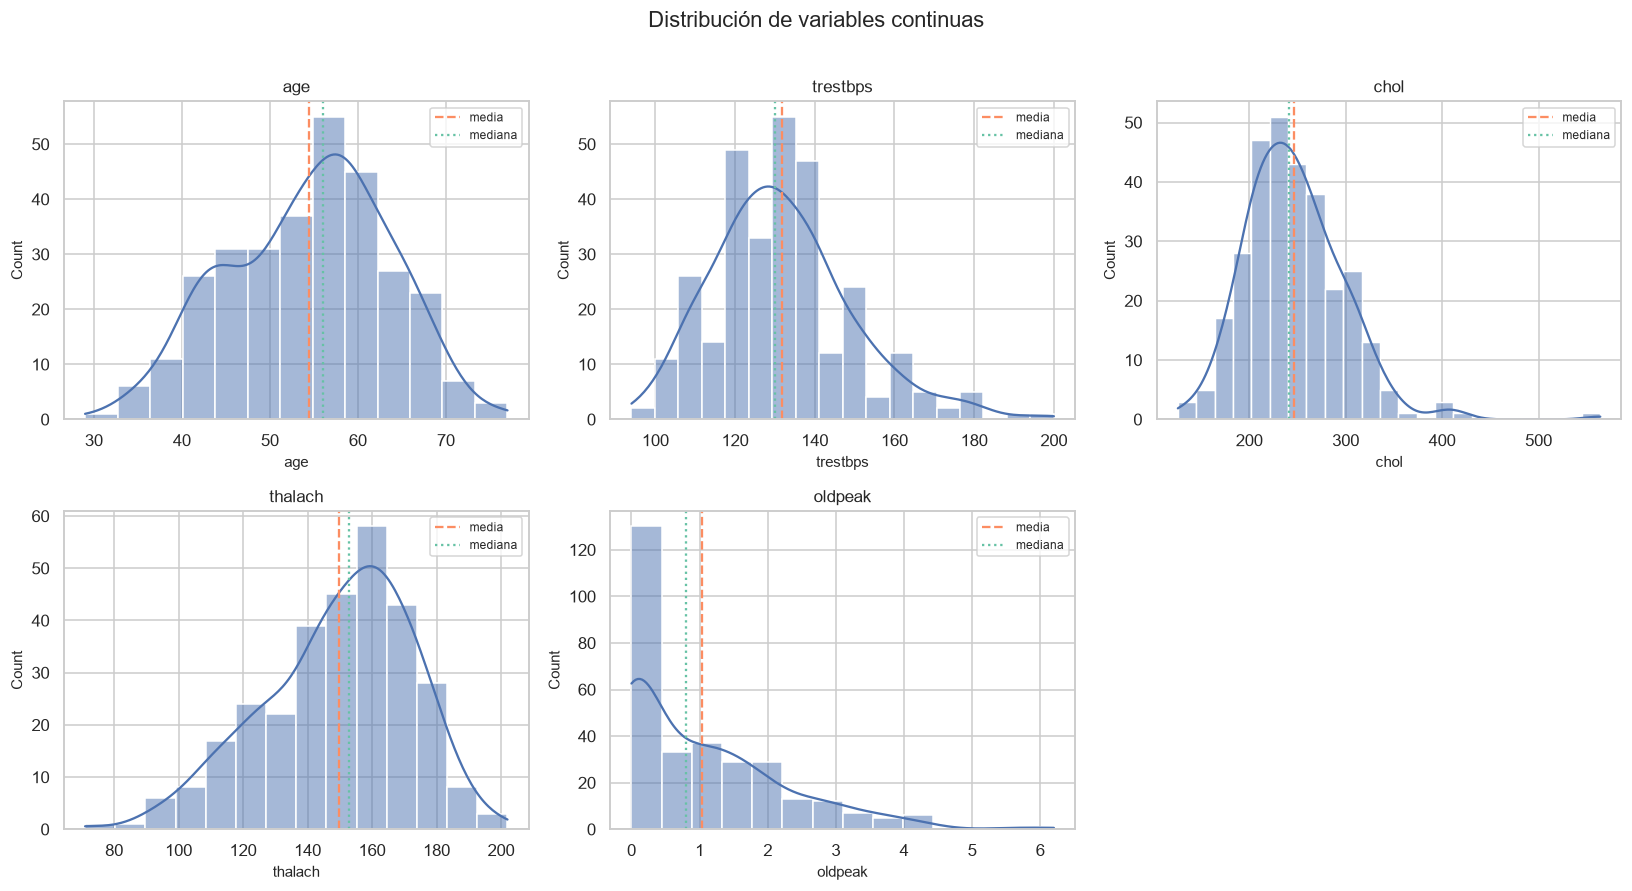

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cont_cols):
    sns.histplot(df[c], kde=True, ax=ax, color="#4c72b0", edgecolor="white")
    ax.axvline(df[c].mean(), color="#fc8d62", linestyle="--", label="media")
    ax.axvline(df[c].median(), color="#66c2a5", linestyle=":", label="mediana")
    ax.set_title(c)
    ax.legend(fontsize=8)
axes.ravel()[-1].axis("off")
plt.suptitle("Distribución de variables continuas", y=1.01)
plt.tight_layout()
plt.show()

**Observaciones**

- `age`: distribución aproximadamente simétrica, centrada en 54.4 años (rango 29–77). Sin outliers por IQR.
- `trestbps`: media 131.7 mm Hg, mediana 130, con cola derecha moderada (asimetría 0.71) y 9 outliers altos.
- `chol`: media 246.7 mg/dl, mediana 241, cola derecha marcada (asimetría 1.14) y un máximo de 564. Es la variable con mayor curtosis (4.49): cola pesada.
- `thalach`: media 149.6 lpm, mediana 153, cola izquierda (asimetría −0.54). Los valores bajos son los clínicamente relevantes.
- `oldpeak`: mediana 0.8, pero **32.7% de ceros** y cola derecha (asimetría 1.27). Es una variable “cero-inflada”: muchos pacientes no tienen depresión del ST.

**Implicancia para los modelos**

- Los árboles **no necesitan escalado** ni normalización: los splits se basan en umbrales y en el orden de los valores actuales. Una transformación monótona (log, raíz, estandarización) no cambia el árbol.
- La asimetría y los ceros de `oldpeak` no son un problema para el árbol, pero sí deben tenerse en cuenta al interpretar los cortes: es probable que el primer split separe “oldpeak = 0” de “oldpeak > 0”.

### 5.2 Variables categóricas

Frecuencias absolutas y relativas de cada categoría. Los porcentajes se calculan sobre los casos no faltantes.

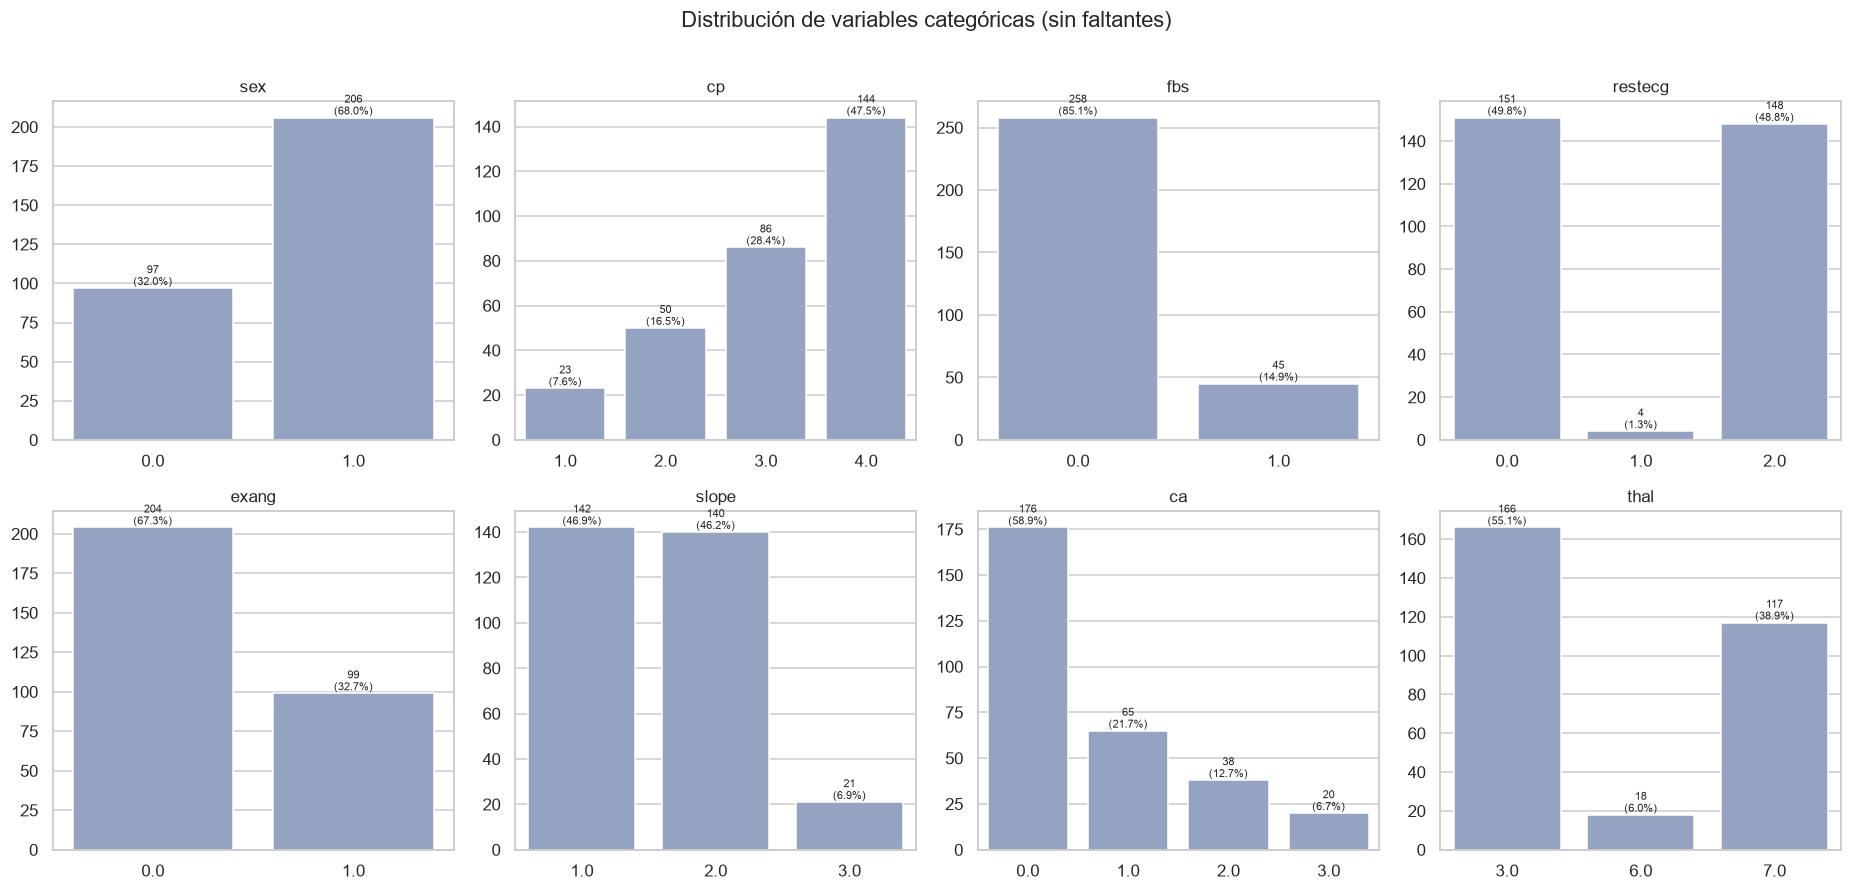

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    orden = sorted(df[c].dropna().unique())
    sns.countplot(data=df, x=c, order=orden, ax=ax, color="#8da0cb")
    total = df[c].notna().sum()
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(f"{int(h)}\n({100 * h / total:.1f}%)",
                        (p.get_x() + p.get_width() / 2, h),
                        ha="center", va="bottom", fontsize=7)
    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle("Distribución de variables categóricas (sin faltantes)", y=1.01)
plt.tight_layout()
plt.show()

**Observaciones**

- `sex`: 206 hombres (68.0%) y 97 mujeres (32.0%). Hay desbalance de sexo, algo habitual en cohortes cardiológicas de la época.
- `cp`: la categoría 4 (asintomático) es la más frecuente (144, 47.5%), seguida de 3 (86, 28.4%), 2 (50, 16.5%) y 1 (23, 7.6%).
- `fbs`: 258 pacientes (85.1%) con glucemia ≤ 120 mg/dl y 45 (14.9%) por encima.
- `restecg`: 151 normales (49.8%), 148 con hipertrofia ventricular izquierda (48.8%) y solo 4 con anomalía ST-T (1.3%).
- `exang`: 204 sin angina inducida (67.3%) y 99 con angina (32.7%).
- `slope`: 142 ascendente (46.9%), 140 plano (46.2%) y 21 descendente (6.9%).
- `ca`: 176 con 0 vasos (58.9%), 65 con 1 (21.7%), 38 con 2 (12.7%), 20 con 3 (6.7%) y 4 faltantes (1.3% del total).
- `thal`: 166 normales (55.1%), 117 con defecto reversible (38.9%), 18 con defecto fijo (6.0%) y 2 faltantes (0.7% del total).

**Implicancia para los modelos**

- Las variables con categorías raras (`restecg = 1`, `thal = 6`, `ca = 3`, `slope = 3`) son las candidatas a generar hojas inestables.
- `sex` está desbalanceado, pero no es una categoría rara. Es una variable clínicamente legítima; su peso en el modelo se evaluará en la etapa de modelado.

> **Alcance del EDA:** este notebook se concentra en la estructura, la calidad y la distribución univariada de los datos. El análisis de asociación con el target y la comparación de modelos se abordan en la etapa de modelado, para no duplicar el análisis ni adelantar conclusiones sin validación.

---
## 6. Problemas detectados y decisiones tomadas

Esta sección consolida todo el análisis en una tabla de trazabilidad: **problema → evidencia → decisión → riesgo/mitigación**. Es la sección que alimenta directamente el informe (apartado “Descripción de la solución implementada — problemas encontrados”).

| # | Problema | Evidencia | Decisión | Riesgo / mitigación |
|---|---|---|---|---|
| 1 | Valores faltantes | 6 filas (1.98%): `ca` 4, `thal` 2 | Imputar mediana/moda; comparar contra eliminar | Sesgo mínimo; imputar **solo con train** para evitar leakage |
| 2 | Tipos mal inferidos | Categóricas cargadas como `float64` por los NaN | Convertir a `Int64`/`category` antes de modelar | Evita que el árbol trate categorías como números |
| 3 | Categorías raras | `restecg=1` (4), `thal=6` (18), `ca=3` (20), `slope=3` (21) | Mantener; usar `min_samples_leaf`; evaluar agrupar `restecg=1` con `2` | Ramas inestables; validar con CV y sensibilidad |
| 4 | Outliers | `trestbps` 9, `chol` 5, `oldpeak` 5, `thalach` 1 (IQR) | No recortar; árboles robustos | Posible corte aislado; controlar con `min_samples_leaf` |
| 5 | Desbalance de clases | Binario 54.1/45.9; multiclase 54.1/18.2/11.9/11.6/4.3 | Binario; split estratificado; F1/recall/AUC | Multiclase requeriría `class_weight` y más cuidado |
| 6 | Escalas dispares | `chol` 126–564 vs. `oldpeak` 0–6.2 | No escalar | Árboles invariantes a escala; no afecta |
| 7 | Codificación para modelos | DT nativo vs. RF numérico | DT multiway para categóricas; RF one-hot; ablación DT one-hot | Comparación no 100% “apples-to-apples”; documentar |
| 8 | Target ordinal | `num` 0–4 con severidad | Binarizar `num > 0` | Pierde gradación; extensión multiclase |
| 9 | Fuga de información | Sin IDs; target separado | Excluir `num` de X; split antes de imputar/codificar | Evitar leakage |
| 10 | Varianza de estimación | 303 filas; test único puede ser inestable | 80/20 estratificado + CV 5-fold; media ± desvío; seed 42 | Reportar intervalos, no un solo número |
| 11 | Reproducibilidad | Colab y librerías cambiantes | Semillas fijas, versiones, código documentado | Reejecutable por la cátedra |

### 6.1 Decisiones de preprocesamiento (para la etapa de modelado)

| Tema | Decisión | Justificación |
|---|---|---|
| Target | Binario `num > 0` | Benchmark estándar; clases balanceadas; métricas interpretables |
| Faltantes | Imputar `ca` con mediana y `thal` con moda | Solo 6 filas; preserva el tamaño muestral; variables clínicamente relevantes |
| Ajuste de imputación | Fit en train, transform en test | Evita leakage |
| Categóricas | DT: split multiway nativo; RF: one-hot | Cada modelo usa su representación natural |
| Escalado | Ninguno | Árboles invariantes a transformaciones monótonas |
| Outliers | Mantener | Valores plausibles; árboles robustos |
| Categorías raras | Mantener + `min_samples_leaf` | Preserva información clínica; controla sobreajuste |
| Desbalance | Sin remuestreo | Binario está razonablemente balanceado |
| Split | 80/20 estratificado, `random_state=42` | Test representativo y reproducible |
| Validación | `StratifiedKFold(n_splits=5)`, repetido con semillas | Estimación más estable que un solo split |
| Métricas | Accuracy, precisión, recall, F1, especificidad, ROC-AUC, matriz de confusión | Cubre distintos aspectos del rendimiento |
| Selección de modelo | Solo con train/CV, nunca con test | Evita sobreajuste al test |

### 6.2 Consideraciones específicas del algoritmo DT

El pseudocódigo de la cátedra (Liu, *Web Data Mining*) asume atributos categóricos y elimina el atributo usado (`A - {Ag}`). Nuestro dataset tiene **5 variables continuas**, así que hay que tomar decisiones explícitas:

1. **Splits binarios por umbral para continuas.** Se ordenan los valores, se prueban puntos medios y se elige el corte de mayor reducción de impureza. Es la adaptación tipo C4.5.
2. **Splits multiway para categóricas.** Se crea una rama por cada valor observado, como en el pseudocódigo.
3. **Reutilización de atributos continuos.** El pseudocódigo elimina el atributo usado. Con continuas, eso impide volver a cortar la misma variable con otro umbral. Se implementará un flag `allow_continuous_reuse` (default `True`) y se reportará la ablación contra el comportamiento estricto.
4. **Umbral de parada (`threshold`).** Es un hiperparámetro de pre-poda: si la mejor reducción de impureza es menor que el umbral, se crea una hoja con la clase mayoritaria. Se barrerá en la etapa de experimentación.
5. **Criterio de impureza.** Se implementarán **entropía** y **Gini**; se compararán.
6. **Empates.** Se resolverán de forma determinística (orden de columnas) para que el árbol sea reproducible.
7. **Valores no vistos en predicción.** Si una rama no existe, se devuelve la clase mayoritaria del nodo.

Estas decisiones se documentarán en el informe y se justificarán como adaptaciones necesarias del pseudocódigo al tipo de datos.

### 6.3 Chequeo de sensibilidad: eliminar vs. imputar faltantes

Como solo hay 6 filas con faltantes, comparamos las dos estrategias para verificar que la decisión no cambia las conclusiones. Este chequeo es **exploratorio** (todavía no hay modelo); en la etapa de modelado se repetirá con métricas.

In [23]:
df_drop = df.dropna().copy()

df_imp = df.copy()
for c in ["ca", "thal"]:
    df_imp[c] = df_imp[c].fillna(df_imp[c].median())

comparacion = pd.DataFrame({
    "estrategia": ["Eliminar filas con faltantes", "Imputar mediana/moda"],
    "n": [len(df_drop), len(df_imp)],
    "tasa_enfermo_%": [round(100 * df_drop["target"].mean(), 2),
                       round(100 * df_imp["target"].mean(), 2)],
    "edad_media": [round(df_drop["age"].mean(), 2),
                   round(df_imp["age"].mean(), 2)],
    "colesterol_medio": [round(df_drop["chol"].mean(), 2),
                         round(df_imp["chol"].mean(), 2)],
    "thalach_media": [round(df_drop["thalach"].mean(), 2),
                      round(df_imp["thalach"].mean(), 2)],
})
comparacion

,estrategia,n,tasa_enfermo_%,edad_media,colesterol_medio,thalach_media
0,Eliminar filas con faltantes,297,46.130,54.540,247.350,149.600
1,Imputar mediana/moda,303,45.870,54.440,246.690,149.610


**Resultado:** las diferencias son mínimas (la tasa de enfermedad cambia menos de 1 punto porcentual y las medias de las continuas se mueven en décimas). La decisión de imputar **no altera las conclusiones del EDA** y permite conservar las 303 filas.

### 6.3.1 Vista previa de la tabla de modelado

La siguiente celda construye, **solo a modo de vista previa**, una tabla con el target binario, los faltantes imputados y los tipos corregidos. No guarda archivos: la tabla definitiva se armará en el notebook de modelado.

In [24]:
# Vista previa de la tabla lista para modelar (sin guardar archivos)
# Se excluye `num` para evitar fuga de información: el target es `target`.
df_model = df.drop(columns=["num"]).copy()

# Imputación simple solo para la vista previa
for c in ["ca", "thal"]:
    df_model[c] = df_model[c].fillna(df_model[c].median())

# Tipos: categóricas como categoría, continuas como float
for c in cat_cols:
    df_model[c] = df_model[c].astype("int64").astype("category")
for c in cont_cols:
    df_model[c] = df_model[c].astype("float64")

print("Faltantes luego de imputar:", int(df_model.isna().sum().sum()))
print("Dimensiones:", df_model.shape, "(13 features + target)")
df_model.head()

Faltantes luego de imputar: 0
Dimensiones: (303, 14) (13 features + target)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.000,1,1,145.000,233.000,1,2,150.000,0,2.300,3,0,6,0
1,67.000,1,4,160.000,286.000,0,2,108.000,1,1.500,2,3,3,1
2,67.000,1,4,120.000,229.000,0,2,129.000,1,2.600,2,2,7,1
3,37.000,1,3,130.000,250.000,0,0,187.000,0,3.500,3,0,3,0
4,41.000,0,2,130.000,204.000,0,2,172.000,0,1.400,1,0,3,0


### 6.4 Riesgos que NO se detectaron

Para que el análisis sea completo, también conviene dejar constancia de lo que se verificó y no representó un problema:

- **No hay duplicados exactos.**
- **No hay columnas constantes.**
- **No hay valores fuera de dominio.**
- **No hay identificadores ni variables con fuga directa del target.**
- **No hay valores centinela** (`0`, `-1`, `999`) en variables donde serían inválidos.
- **No hay un bloque sistemático de faltantes** (solo 6 filas aisladas).

Esto permite avanzar a la etapa de modelado sin una limpieza profunda adicional.

---
## 7. Conclusiones del EDA

### 7.1 Resumen

| Aspecto | Hallazgo / decisión |
|---|---|
| Filas | 303 |
| Columnas | 14 (13 features + target) |
| Faltantes | 6 filas (1.98%): `ca` = 4, `thal` = 2 |
| Duplicados | 0 |
| Target binario | 164 sanos (54.1%) / 139 enfermos (45.9%) |
| Target multiclase | 164 / 55 / 36 / 35 / 13 |
| Baseline trivial | 54.1% de accuracy (predecir siempre “sano”) |
| Continuas | `age`, `trestbps`, `chol`, `thalach`, `oldpeak` |
| Categóricas | `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal` |
| Categorías raras | `restecg=1` (4), `thal=6` (18), `ca=3` (20), `slope=3` (21) |
| Outliers (IQR) | 20 en total: `trestbps` 9, `chol` 5, `oldpeak` 5, `thalach` 1 |
| Escalado | No necesario para árboles |
| Protocolo | Split 80/20 estratificado + CV 5-fold; `random_state=42` |

### 7.2 Hallazgos principales

1. **El dataset es pequeño pero limpio.** 303 filas, sin duplicados, sin valores fuera de dominio y con solo 6 faltantes. Es ideal para implementar y auditar un árbol desde cero.
2. **El target binario está balanceado.** 54.1/45.9 permite usar accuracy sin que sea engañosa, pero igual conviene reportar sensibilidad, especificidad y F1.
3. **Las variables continuas tienen escalas y formas distintas.** `chol` y `oldpeak` tienen cola derecha; `thalach` tiene cola izquierda; `oldpeak` está inflada en ceros. Los árboles no necesitan escalado, pero estas particularidades deben tenerse en cuenta al interpretar los cortes.
4. **Hay categorías raras y outliers.** `restecg = 1` tiene solo 4 casos y hay 20 outliers por IQR. No se eliminan, pero obligan a controlar la complejidad del árbol (`min_samples_leaf`, `threshold`) y a reportar sensibilidad.
5. **El dataset no requiere una limpieza profunda.** No hay duplicados, columnas constantes, valores fuera de dominio, valores centinela ni identificadores. El único problema de calidad relevante son los 6 faltantes.
6. **Hay limitaciones de representatividad.** Cohorte histórica de un solo centro, predominantemente masculina y derivada a angiografía; los resultados no deben generalizarse sin cautela.
7. **El baseline trivial es 54.1%.** Un modelo útil debe superar claramente ese valor; en la literatura, modelos simples sobre Cleveland suelen ubicarse en 75–85% de accuracy.

### 7.3 Hipótesis para la etapa de modelado

- Un DT bien parametrizado debería alcanzar **~75–85% de accuracy** en test, con recall razonable.
- RF debería **mejorar** al DT en accuracy y estabilidad, a costa de perder interpretabilidad y aumentar el costo de entrenamiento.
- El `threshold` de pre-poda y `min_samples_leaf` van a tener un efecto visible en el tamaño del árbol y en el overfitting.
- Las variables clínicas relevantes deberían aparecer en los primeros niveles del árbol; se verificará con la estructura entrenada.
- Las variables con poca señal o con categorías raras deberían quedar fuera o en niveles profundos; se verificará con la importancia y el árbol.